In [1]:
import torch
from torchvision import datasets, transforms
from matplotlib import pyplot
from PIL import Image
import numpy
import pandas
from model_training import CNN

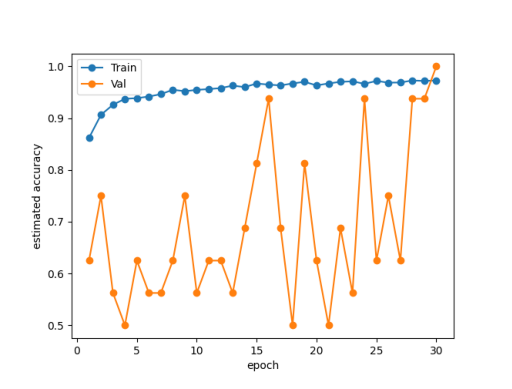

In [2]:
# See how accuracy varied during the training.
image = Image.open('accuracy_logging.png')
image = numpy.array(image)
figure, axis = pyplot.subplots()
axis.set_axis_off()
axis.imshow(image);
# For some reason there was only 16 images in the validation set. So the validation accuracy
# isn't too reliable of a measure, and that's why the Val curve looks wonky. But the test set results 
# still ended up pretty good.

In [4]:
# Load test set and our model.

image_size = 256

transform = transforms.Compose([transforms.Resize((image_size, image_size)), 
                                transforms.ToTensor()])

data_folder_path = r"C:\Users\tbaka\Jupyter\Data Science Projects\medical_detection\chest_xray\test"
test_dataset = datasets.ImageFolder(data_folder_path, transform=transform)

model = CNN()
print(sum(p.numel() for p in model.parameters()), 'parameters')
model.load_state_dict(torch.load("model_weights.pth", weights_only=True))
model.eval();

652602 parameters


In [6]:
# Returns predicted values and corresponding true values.
def predict(dataset):
    global model, image_size
    n = len(dataset)
    predictions = numpy.zeros(n)
    truth = numpy.zeros(n)
    with torch.no_grad():
        for i in range(n):
            x, y = dataset.__getitem__(i)
            logits = model(x.view((1, 3, image_size, image_size))).view((2,))
            probabilities = torch.softmax(logits, dim=0)
            _, predicted = torch.max(probabilities, dim=0)
            predictions[i] = predicted
            truth[i] = y
    return predictions, truth

In [9]:
y_hat, y = predict(test_dataset)
print((y_hat == y).mean())
confusion_table = pandas.crosstab(y, y_hat, rownames=['Truth'], colnames=['Predicted'])
confusion_table

0.8894230769230769


Predicted,0.0,1.0
Truth,,
0.0,176,58
1.0,11,379


In [10]:
# The model has an accuracy of about 89% on the test images. And it correctly predicted 97% of pneumonia images.
379 / (11 + 379)

0.9717948717948718

In [ ]:
# The more common error was predicting pneumonia when the truth is normal. And
# this is by far the preferable error type to occur when looking for an illness.

In [4]:
# 62.5% of the test set was pneumonia images. So it wasn't too badly lopsided.
a = 11 + 379
b = 176 + 58
a / (a + b)

0.625

In [ ]:
# To improve things further, we could try changing the probability threshold when predicting pneumonia or creating
# other models for an ensemble. More data with a larger network would probably help as well. 
# But I think our results are solid.

In [5]:
# We can also look at some of the model's predctions.
from torchvision.transforms import ToPILImage
topil = ToPILImage()
def show_random_predictions(dataset, rows=5, cols=3):
    global image_size, model, topil
    sample = numpy.random.randint(len(dataset), size=rows * cols)
    figure, axes = pyplot.subplots(rows, cols)
    figure.tight_layout()
    count = 0
    for i in range(rows):
        for j in range(cols):
            k = sample[count]
            
            x, y = dataset.__getitem__(k)
            logits = model(x.view((1, 3, image_size, image_size))).view((2,))
            p = torch.softmax(logits, dim=0)
            _, prediction = torch.max(p, dim=0)
            title = f'predicted: {prediction.item()}, truth:' + str(y)

            x = topil(x)
            axes[i][j].imshow(numpy.array(x))
            axes[i][j].set_title(title)
            axes[i][j].set_axis_off()
            count += 1

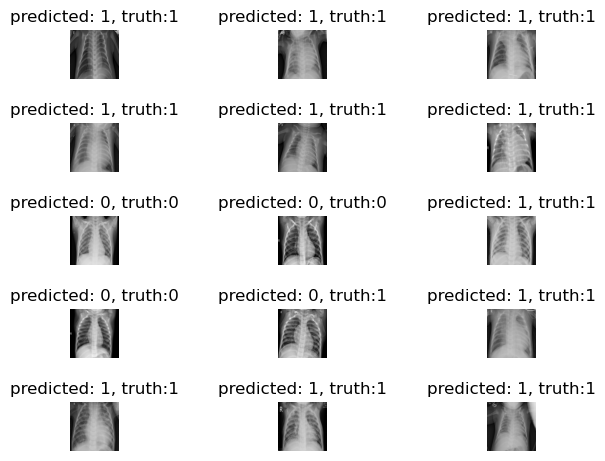

In [9]:
show_random_predictions(test_dataset)